# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import AgriFieldNetDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose
import matplotlib.pyplot as plt
import numpy as np

## Visualize images and masks

New train/val/test split

In [ ]:
# all bands images
dataset_config = {
    "data_dir": "./data/AgriFieldNet/",
    "csv_file": "./data/AgriFieldNet/agrifieldnet_train.csv",
    "selection": "all"
}
dataset = AgriFieldNetDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 727


In [ ]:
# user-defined bands
dataset_config = {
    "data_dir": "./data/AgriFieldNet/",
    "csv_file": "./data/AgriFieldNet/agrifieldnet_train.csv",
    "selection": "bands",
    "bands_s2": ["B01","B02","B03","B04","B05","B06"]
}
dataset = AgriFieldNetDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 727


Original train/test split

Total number of patches: 1165


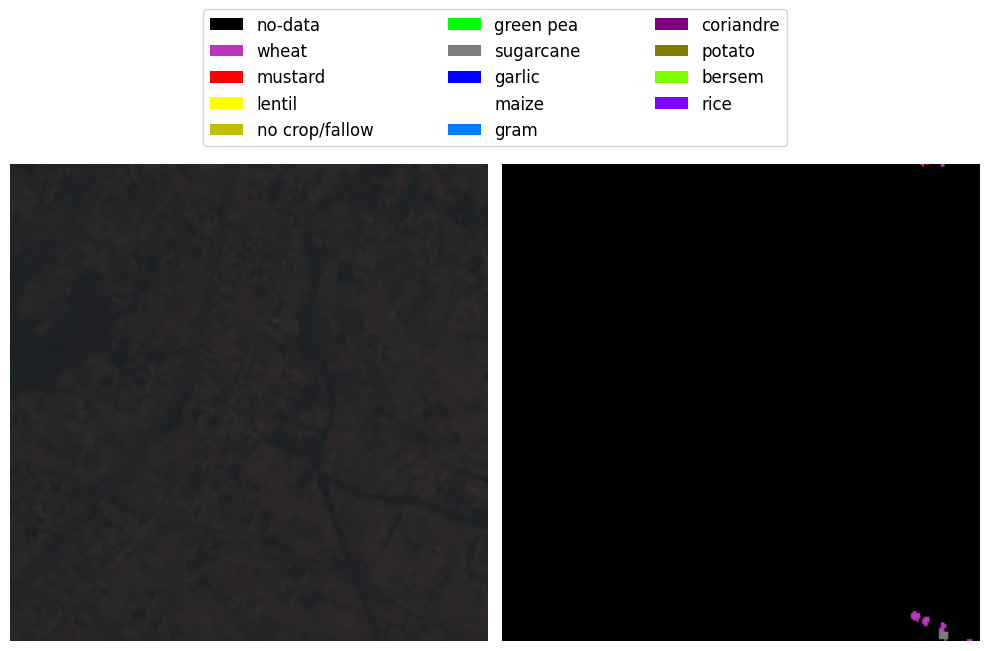

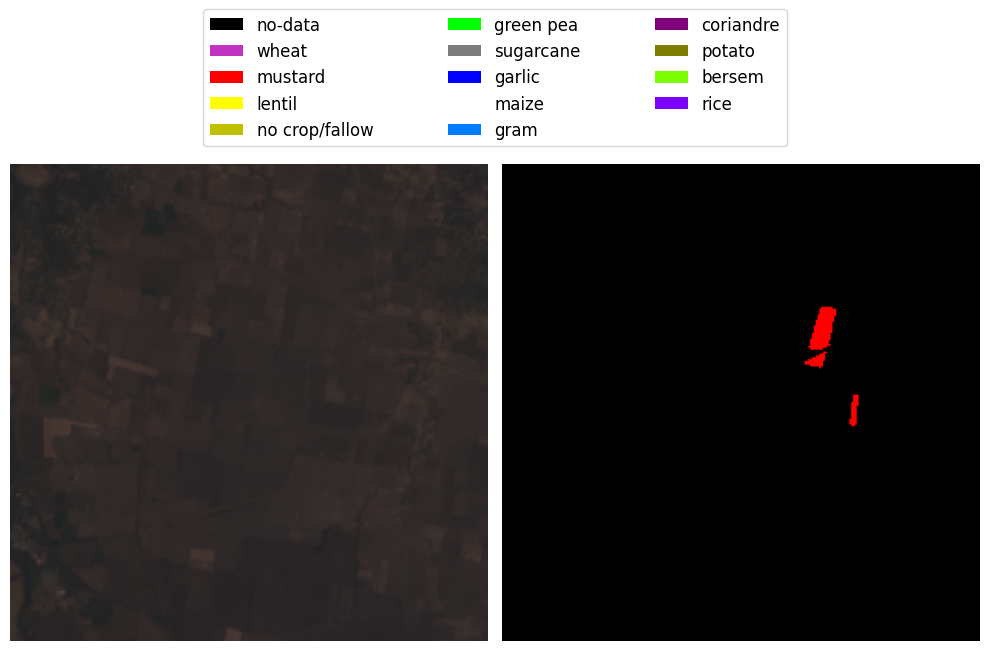

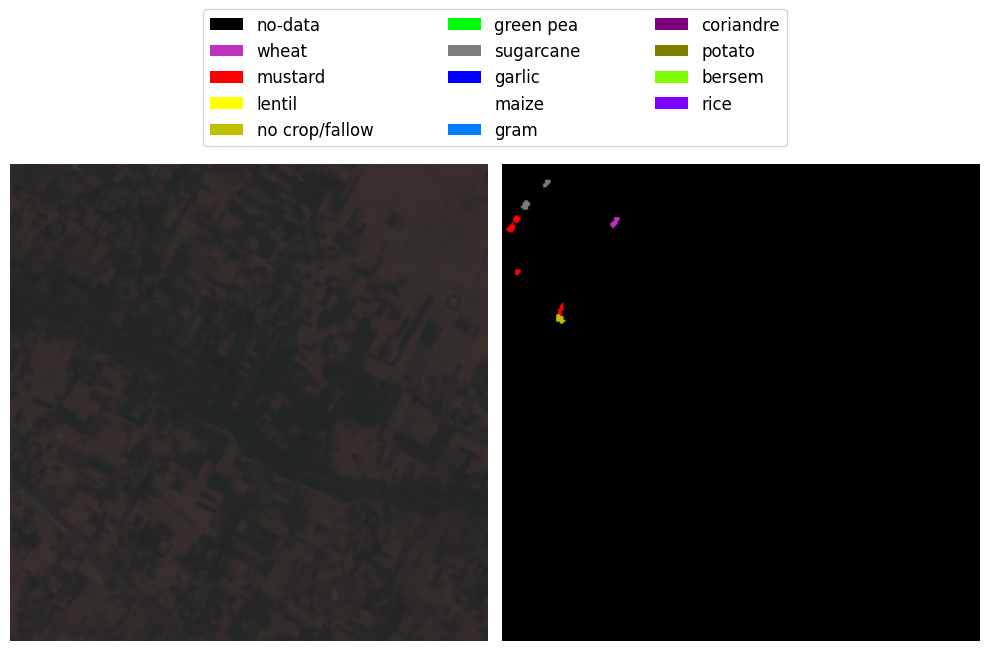

In [ ]:
dataset_config = {
    "data_dir": "./data/AgriFieldNet/train",
    "selection": "rgb"
}
dataset = AgriFieldNetDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(350);
dataset.show_image(600);

In [19]:
dataset.data_distribution_table()

,Number of pixels
no-data,76161208.0
wheat,75118.0
mustard,46818.0
lentil,2883.0
no crop/fallow,36397.0
green pea,531.0
sugarcane,5820.0
garlic,0.0
maize,3150.0
gram,8773.0


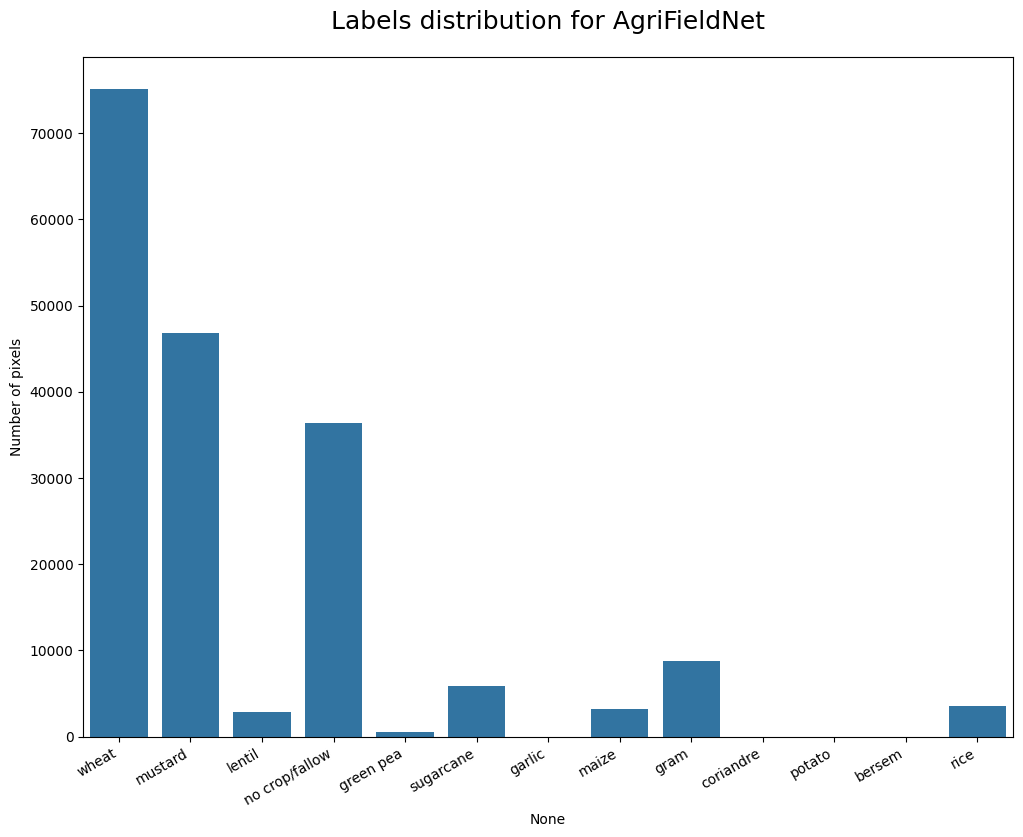

In [20]:
dataset.data_distribution_barchart();

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/AgriFieldNet/train",
    "selection": "rgb",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = AgriFieldNetDataset(train_dataset_config)
len(train_dataset)

1165

## Create the model

In [ ]:
epochs = 10
model_directory = "./data/AgriFieldNet"
model_config = {
    "num_classes": 14, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [70]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-04-14 08:18:24,787 INFO Starting training.
training: 100%|██████████| 146/146 [00:14<00:00, 10.02it/s]
2025-04-14 08:18:39,413 INFO epoch: 1, time: 15, loss:  0.77283
testing on train set: 100%|██████████| 146/146 [00:06<00:00, 21.83it/s]
2025-04-14 08:18:47,980 INFO IOU:0.848508658517566, IOU mean:0.06075307317323945, IOU per Class:[0.85054302 0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.        ]
training: 100%|██████████| 146/146 [00:14<00:00, 10.23it/s]
2025-04-14 08:19:02,258 INFO epoch: 2, time: 15, loss:  0.44038
testing on train set: 100%|██████████| 146/146 [00:06<00:00, 21.18it/s]
2025-04-14 08:19:09,168 INFO IOU:0.9951494943326837, IOU mean:0.07125247508598061, IOU per Class:[0.99753465 0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.        ]
training: 100%|██████████| 146/146 [00:14<00:00, 10.16it/s]
2025-04-14 08:19:23,546

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/AgriFieldNet/test",
    "selection": "rgb",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = AgriFieldNetDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/AgriFieldNet/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

47


2025-04-14 08:38:01,871 INFO Loading checkpoint /home/dragik/data/FAIR_EO/AgriFieldNet/checkpoint.pth.tar
2025-04-14 08:38:02,355 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/AgriFieldNet/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 12/12 [00:00<00:00, 14.00it/s]


[{'IOU': 0.999267578125,
  'IOU mean': 0.07137625558035714,
  'IOU per Class': array([0.99926758, 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        ])}]

## Predictions

2025-04-14 08:39:15,919 INFO Loading checkpoint /home/dragik/data/FAIR_EO/AgriFieldNet/checkpoint.pth.tar
2025-04-14 08:39:16,347 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/AgriFieldNet/checkpoint.pth.tar at epoch 11


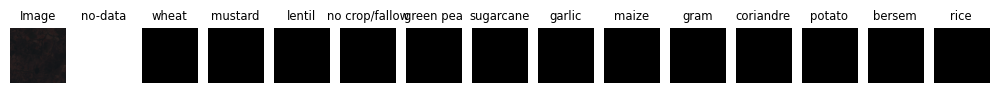

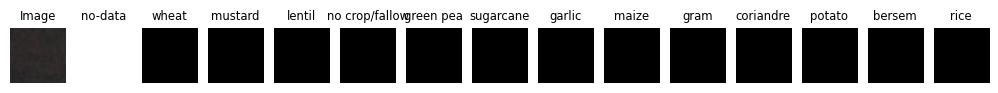

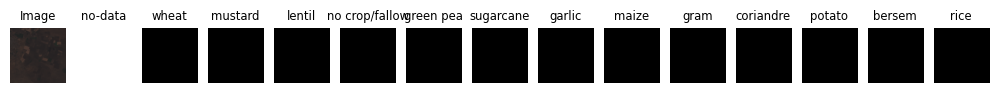

In [ ]:
model_path = "./data/AgriFieldNet/checkpoint.pth.tar"
labels = ["no-data","wheat","mustard","lentil","no crop/fallow","green pea","sugarcane","garlic","maize","gram","coriandre","potato","bersem","rice"]
transform = MinMaxNormTranspose()
plt.rcParams.update({'font.size': 7})
model.load_model(model_path)

imageB02 = image_loader('./data/AgriFieldNet/test/source/B02/ref_agrifieldnet_competition_v1_source_2d2a5_B02_10m.tif')
imageB03 = image_loader('./data/AgriFieldNet/test/source/B03/ref_agrifieldnet_competition_v1_source_2d2a5_B03_10m.tif')
imageB04 = image_loader('./data/AgriFieldNet/test/source/B04/ref_agrifieldnet_competition_v1_source_2d2a5_B04_10m.tif')
image = np.dstack((imageB04,imageB03,imageB02))
fig = model.predict_masks(image, labels, transform)

imageB02 = image_loader('./data/AgriFieldNet/test/source/B02/ref_agrifieldnet_competition_v1_source_8a35c_B02_10m.tif')
imageB03 = image_loader('./data/AgriFieldNet/test/source/B03/ref_agrifieldnet_competition_v1_source_8a35c_B03_10m.tif')
imageB04 = image_loader('./data/AgriFieldNet/test/source/B04/ref_agrifieldnet_competition_v1_source_8a35c_B04_10m.tif')
image = np.dstack((imageB04,imageB03,imageB02))
fig = model.predict_masks(image, labels, transform)

imageB02 = image_loader('./data/AgriFieldNet/test/source/B02/ref_agrifieldnet_competition_v1_source_5133b_B02_10m.tif')
imageB03 = image_loader('./data/AgriFieldNet/test/source/B03/ref_agrifieldnet_competition_v1_source_5133b_B03_10m.tif')
imageB04 = image_loader('./data/AgriFieldNet/test/source/B04/ref_agrifieldnet_competition_v1_source_5133b_B04_10m.tif')
image = np.dstack((imageB04,imageB03,imageB02))
fig = model.predict_masks(image, labels, transform)